In [113]:
import os

import keras
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
import tensorflow_datasets as tfds
from keras import layers, models, regularizers
from keras.callbacks import EarlyStopping
from keras.optimizers import Adam
from sklearn.datasets import load_digits
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

In [114]:
#Для ноута
#tf.config.threading.set_intra_op_parallelism_threads(4)
#tf.config.threading.set_inter_op_parallelism_threads(1)

print("TensorFlow:", tf.__version__)
print("GPU для TensorFlow:", tf.config.list_physical_devices("GPU"))

gpus = tf.config.list_physical_devices("GPU")

for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

TensorFlow: 2.21.0
GPU для TensorFlow: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [115]:
ds_train, ds_val, ds_test = tfds.load(
    "svhn_cropped",
    split=[
        "train[:90%]",
        "train[90%:]",
        "test"
    ],
    as_supervised=True
)

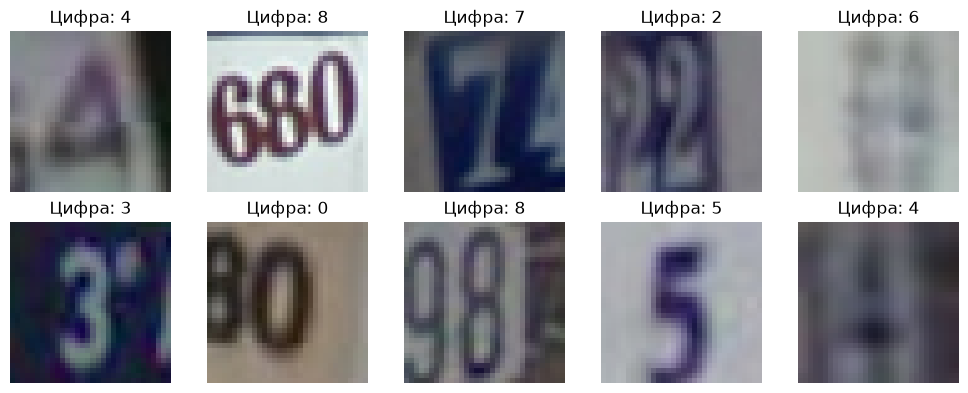

In [116]:
fig, axes = plt.subplots(2,5,figsize=(10,4))

for i, (image, label) in enumerate(ds_train.take(10)):
    axes.flat[i].imshow(image.numpy())
    axes.flat[i].set_title(f"Цифра: {int(label.numpy())}")
    axes.flat[i].axis("off")

plt.tight_layout()
plt.show()

In [117]:
BATCH_SIZE = 128

train_ds = (
    ds_train
    .shuffle(10000, seed=42)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
    #1 для ноута
)

val_ds = (
    ds_val
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
    #1 для ноута
)

test_ds = (
    ds_test
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
    #1 для ноута
)

In [ ]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomTranslation(0.1, 0.1),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1),
])

def conv_block_5x5(filters):
    return keras.Sequential([
        layers.Conv2D(filters, (5, 5), padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D((2, 2)),
    ])
    
def conv_block_3x3(filters):
    return keras.Sequential([
        layers.Conv2D(filters, (3, 3), padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D((2, 2)),
    ])

def conv_block_3x3_no_pooling(filters):
    return keras.Sequential([
        layers.Conv2D(filters, (3, 3), padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
    ])


model_cnn = models.Sequential([
    layers.Input(shape=(32, 32, 3)),
    #layers.CenterCrop(height=32, width=28),
    data_augmentation,
    layers.Rescaling(1.0 / 255),
    
    conv_block_5x5(32),
    conv_block_5x5(64),
    conv_block_3x3(128),
    conv_block_3x3_no_pooling(256),
    
    #layers.GlobalAveragePooling2D(),
    layers.Flatten(),
    layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.Dropout(0.3),
    layers.Dense(10, activation='softmax')
])

model_cnn.summary()

Model: "sequential_53"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_48 (Sequential)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_8 (Rescaling)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_49 (Sequential)      │ (None, 16, 16, 32)     │         2,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_50 (Sequential)      │ (None, 8, 8, 64)       │        51,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_51 (Sequential)      │ (None, 4, 4, 128)      │        74,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_52 (Sequential)      │ (None, 4, 4, 256)      │       295,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_8 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 256)            │     1,048,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,475,562 (5.63 MB)

 Trainable params: 1,474,602 (5.63 MB)

 Non-trainable params: 960 (3.75 KB)

In [119]:
model_cnn.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss="sparse_categorical_crossentropy",
    metrics=["sparse_categorical_accuracy"]
)

In [120]:
early_stop = EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=15,
    min_delta=0.002,
    restore_best_weights=True,
    verbose=1
)

os.makedirs("checkpoints", exist_ok=True)
checkpoint_path = "checkpoints/svhn-cnn.keras"

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_path,
    monitor="val_sparse_categorical_accuracy",
    mode="max",
    save_best_only=True,
    save_weights_only=False,
    verbose=1
)

if os.path.exists(checkpoint_path):
    cnn = tf.keras.models.load_model(checkpoint_path)
    print("Загружена сохранённая модель")

Загружена сохранённая модель


In [121]:
history_cnn = model_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=150,
    callbacks=[early_stop, checkpoint]
)

Epoch 1/150


/home/dd/dl-projects/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


509/516 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 1.5876 - sparse_categorical_accuracy: 0.5588
Epoch 1: val_sparse_categorical_accuracy improved from None to 0.77628, saving model to checkpoints/svhn-cnn.keras

Epoch 1: finished saving model to checkpoints/svhn-cnn.keras
516/516 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 1.5804 - sparse_categorical_accuracy: 0.5611 - val_loss: 0.8445 - val_sparse_categorical_accuracy: 0.7763
Epoch 2/150
506/516 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.7762 - sparse_categorical_accuracy: 0.7937
Epoch 2: val_sparse_categorical_accuracy improved from 0.77628 to 0.87155, saving model to checkpoints/svhn-cnn.keras

Epoch 2: finished saving model to checkpoints/svhn-cnn.keras
516/516 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 0.7739 - sparse_categorical_accuracy: 0.7944 - val_loss: 0.5190 - val_sparse_categorical_accuracy: 0.8716
Epoch 3/150
508/516 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.6053 - sparse_categorical_accuracy: 0.8376
Epoch 3: val_sparse_categor

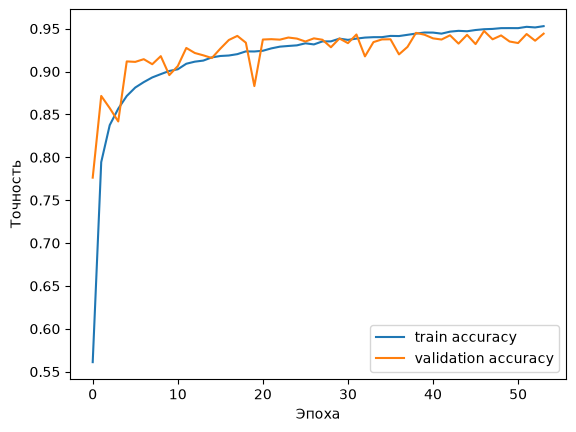

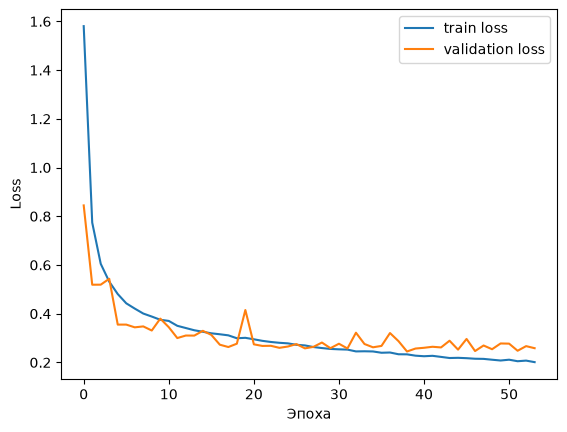

In [122]:
plt.plot(history_cnn.history['sparse_categorical_accuracy'], label='train accuracy')
plt.plot(history_cnn.history['val_sparse_categorical_accuracy'], label='validation accuracy')
plt.xlabel('Эпоха')
plt.ylabel('Точность')
plt.legend()
plt.show()

plt.plot(history_cnn.history['loss'], label='train loss')
plt.plot(history_cnn.history['val_loss'], label='validation loss')
plt.xlabel('Эпоха')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [123]:
test_loss, test_accuracy = model_cnn.evaluate(test_ds)
print(f"Test accuracy: {test_accuracy:.2%}")

204/204 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2377 - sparse_categorical_accuracy: 0.9480
Test accuracy: 94.80%


In [124]:
probs = model_cnn.predict(test_ds, verbose=1)

y_pred = np.argmax(probs, axis=1)

y_true = np.concatenate([
    labels.numpy()
    for images, labels in test_ds
])

204/204 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


In [125]:
print(confusion_matrix(y_true, y_pred))
print(classification_report(y_true, y_pred))

[[1698   11    5    2    1    3   11    2    5    6]
 [  22 4923   39   12   30   10   17   36    5    5]
 [   8   21 4053   22   14    7    6    9    2    7]
 [  14   34   31 2583    8   56    9   10   15  122]
 [   8   41   29    5 2411    2    9    5    4    9]
 [   7   11    9   18    2 2273   41    3    3   17]
 [  21    6    9    4    2   14 1908    0   12    1]
 [   3   77   34    8    2    4    5 1883    0    3]
 [  20    5    7   24    6   13  114    0 1449   22]
 [  39    6   27    3    4    8    3    2    6 1497]]
              precision    recall  f1-score   support

           0       0.92      0.97      0.95      1744
           1       0.96      0.97      0.96      5099
           2       0.96      0.98      0.97      4149
           3       0.96      0.90      0.93      2882
           4       0.97      0.96      0.96      2523
           5       0.95      0.95      0.95      2384
           6       0.90      0.97      0.93      1977
           7       0.97      0.93   

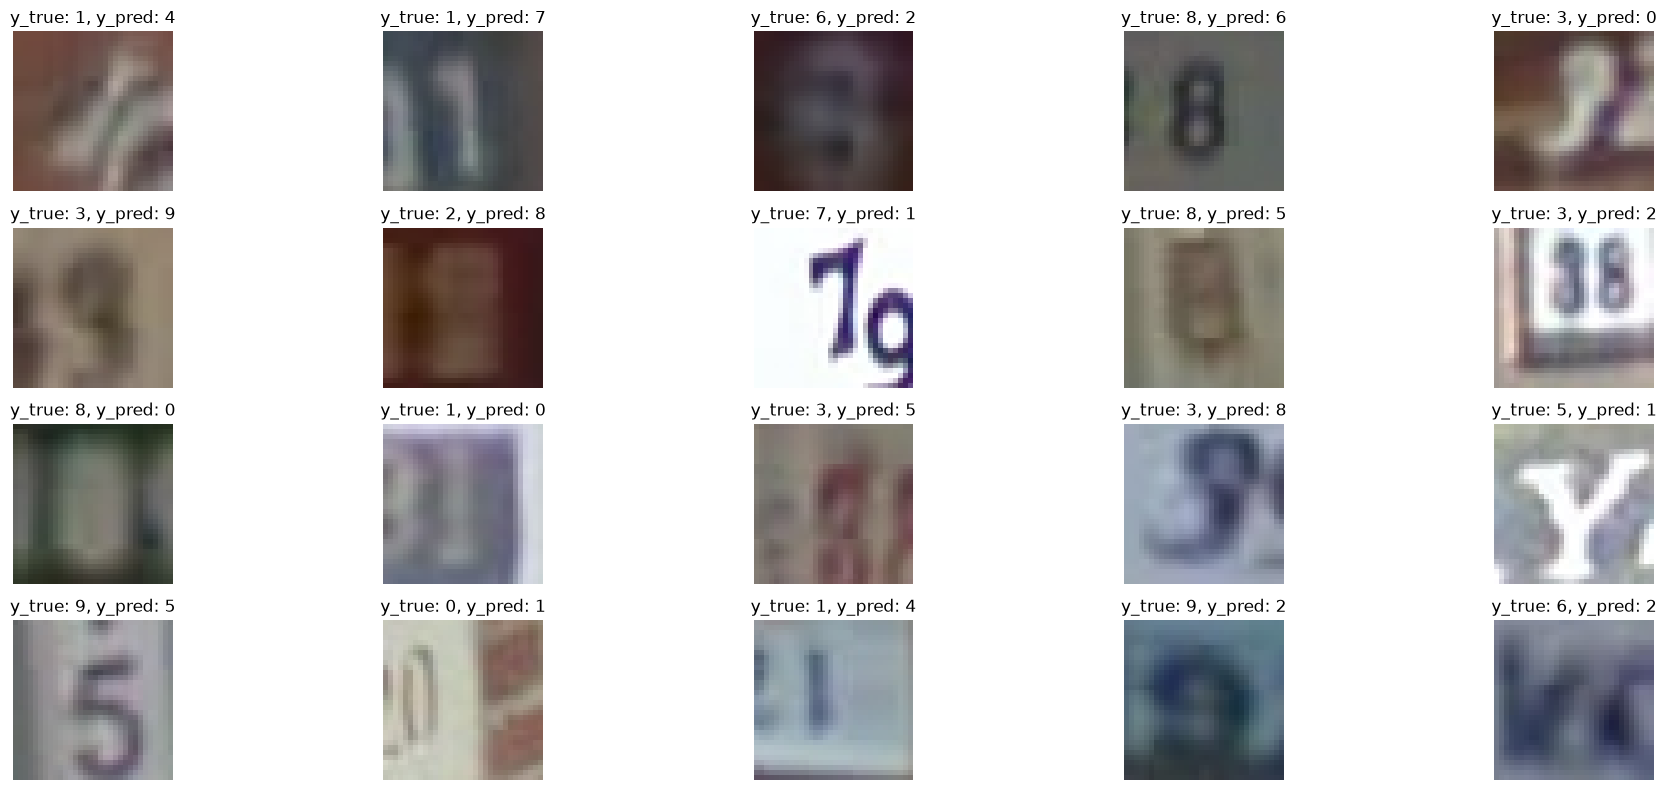

In [126]:
mask = (y_true != y_pred)

fig, axes = plt.subplots(4,5,figsize=(20,8))

j = 0
for i, (image, label) in enumerate(ds_test.take(1000)):
    if mask[i]:
        axes.flat[j].imshow(image.numpy())
        axes.flat[j].set_title(f"y_true: {y_true[i]}, y_pred: {y_pred[i]}")
        axes.flat[j].axis("off")
        j += 1
    if j >= 20:
        break

plt.tight_layout()
plt.show()
        